# 🌍 GREEN MIRAGE
## Is the World Really Going Green?

### A Data-Driven Investigation into Renewable Energy Growth and Fossil Fuel Dependence

### Project Overview

Green Mirage is a Data Science project that investigates whether the growing adoption of renewable energy is actually reducing the world's dependence on fossil fuels.

Using publicly available global energy data, this project compares five countries: India, China, Germany, Brazil, and the United States.

### Research Objectives

- Analyze renewable energy growth over time.
- Examine fossil fuel consumption patterns.
- Compare energy transitions across five countries.
- Identify trends, patterns, and relationships in energy data.
- Present findings through meaningful visualizations.

### Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

### Dataset Source

Our World in Data – Global Energy Dataset.

In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [137]:
# Official Our World in Data dataset

DATA_URL = "https://catalog.ourworldindata.org/garden/energy/2026-09-10/owid_energy/owid_energy.csv"

# Load CSV into Pandas
df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully!")

# Display dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display first five rows
df.head()

Dataset loaded successfully!
Number of rows: 19494
Number of columns: 130


,country,year,iso_code,population,gdp,bioenergy_electricity_per_capita_kwh,bioenergy_electricity_share_pct,bioenergy_electricity_twh,biofuels_energy_annual_change_pct,biofuels_energy_annual_change_twh,...,total_energy_per_gdp_kwh_per_dollar,total_energy_twh,wind_electricity_per_capita_kwh,wind_electricity_share_pct,wind_electricity_twh,wind_energy_annual_change_pct,wind_energy_annual_change_twh,wind_energy_per_capita_kwh,wind_energy_share_pct,wind_energy_twh
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,1.549794,5.87,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,1.594707,6.46,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,1.528198,6.62,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,1.623391,7.44,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,1.689455,8.39,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN


In [138]:
print("AVAILABLE DATASET COLUMNS:\n")

for column in df.columns:
    print(column)

AVAILABLE DATASET COLUMNS:

country
year
iso_code
population
gdp
bioenergy_electricity_per_capita_kwh
bioenergy_electricity_share_pct
bioenergy_electricity_twh
biofuels_energy_annual_change_pct
biofuels_energy_annual_change_twh
biofuels_energy_per_capita_kwh
biofuels_energy_share_pct
biofuels_energy_twh
coal_electricity_per_capita_kwh
coal_electricity_share_pct
coal_electricity_twh
coal_energy_annual_change_pct
coal_energy_annual_change_twh
coal_energy_per_capita_kwh
coal_energy_share_pct
coal_energy_twh
coal_production_annual_change_pct
coal_production_annual_change_twh
coal_production_per_capita_kwh
coal_production_twh
electricity_carbon_intensity_gco2eq_per_kwh
electricity_demand_per_capita_kwh
electricity_demand_twh
electricity_emissions_mtco2eq
electricity_generation_per_capita_kwh
electricity_generation_twh
electricity_net_imports_share_of_demand_pct
electricity_net_imports_twh
electricity_share_of_total_energy_pct
fossil_fuels_electricity_per_capita_kwh
fossil_fuels_electricity_

In [139]:
required_columns = [
    "country",
    "year",
    "total_energy_twh",
    "renewables_energy_twh",
    "fossil_fuels_energy_twh",
    "renewables_energy_share_pct",
    "fossil_fuels_energy_share_pct"
]

print("CHECKING REQUIRED COLUMNS:\n")

for column in required_columns:
    if column in df.columns:
        print(column, "- Available")
    else:
        print(column, "- Missing")

CHECKING REQUIRED COLUMNS:

country - Available
year - Available
total_energy_twh - Available
renewables_energy_twh - Available
fossil_fuels_energy_twh - Available
renewables_energy_share_pct - Available
fossil_fuels_energy_share_pct - Available


In [140]:
countries = [
    "India",
    "China",
    "Germany",
    "Brazil",
    "United States"
]

print("CHECKING SELECTED COUNTRIES:\n")

available_countries = set(df["country"].dropna())

for country in countries:
    if country in available_countries:
        print(country, "- Found")
    else:
        print(country, "- Not found")

CHECKING SELECTED COUNTRIES:

India - Found
China - Found
Germany - Found
Brazil - Found
United States - Found


In [141]:
# Define the analysis period

start_year = 2000
end_year = 2025

# Filter the dataset

energy_five = df[
    (df["country"].isin(countries)) &
    (df["year"].between(start_year, end_year))
].copy()

print("Filtered dataset created successfully!")

print("Total records:", len(energy_five))

energy_five.head()

Filtered dataset created successfully!
Total records: 130


,country,year,iso_code,population,gdp,bioenergy_electricity_per_capita_kwh,bioenergy_electricity_share_pct,bioenergy_electricity_twh,biofuels_energy_annual_change_pct,biofuels_energy_annual_change_twh,...,total_energy_per_gdp_kwh_per_dollar,total_energy_twh,wind_electricity_per_capita_kwh,wind_electricity_share_pct,wind_electricity_twh,wind_energy_annual_change_pct,wind_energy_annual_change_twh,wind_energy_per_capita_kwh,wind_energy_share_pct,wind_energy_twh
2605,Brazil,2000,BRA,174018278.0,1.739728e+12,45.167671,2.252601,7.86,-12.863340,-11.085152,...,1.016500,1768.432983,0.000000,0.000000,0.00,-50.00000,-0.0010,0.005747,0.000057,0.0010
2606,Brazil,2001,BRA,176301201.0,1.785513e+12,51.162445,2.745397,9.02,-6.261240,-4.701637,...,1.000526,1786.451782,0.170163,0.009131,0.03,3390.00000,0.0339,0.197957,0.001954,0.0349
2607,Brazil,2002,BRA,178503485.0,1.861742e+12,57.533894,2.970612,10.27,8.370486,5.891945,...,0.968966,1803.965820,0.336128,0.017355,0.06,74.78511,0.0261,0.341730,0.003381,0.0610
2608,Brazil,2003,BRA,180622688.0,1.904933e+12,66.104652,3.276709,11.94,-4.669794,-3.562187,...,0.948527,1806.880737,0.332184,0.016466,0.06,0.00000,0.0000,0.337721,0.003376,0.0610
2609,Brazil,2004,BRA,182675144.0,2.038448e+12,68.536964,3.231051,12.52,11.320835,8.232430,...,0.932416,1900.681152,0.328452,0.015484,0.06,0.00000,0.0000,0.333926,0.003209,0.0610


In [142]:
print("FILTERED DATASET INFORMATION")
print("-----------------------------")

print("Number of rows:", energy_five.shape[0])
print("Number of columns:", energy_five.shape[1])

print("\nSelected Countries:")
print(energy_five["country"].unique())

print("\nYear Range:")
print(energy_five["year"].min(), "to", energy_five["year"].max())

FILTERED DATASET INFORMATION
-----------------------------
Number of rows: 130
Number of columns: 130

Selected Countries:
['Brazil' 'China' 'Germany' 'India' 'United States']

Year Range:
2000 to 2025


In [143]:
coverage = energy_five.groupby("country").agg(
    Total_Records=("year", "count"),
    First_Year=("year", "min"),
    Last_Year=("year", "max")
)

print("COUNTRY-WISE DATA COVERAGE")

coverage

COUNTRY-WISE DATA COVERAGE


,Total_Records,First_Year,Last_Year
country,,,
Brazil,26,2000,2025
China,26,2000,2025
Germany,26,2000,2025
India,26,2000,2025
United States,26,2000,2025


In [144]:
print("MISSING VALUES REPORT")
print("---------------------")

missing_values = energy_five[required_columns].isnull().sum()

print(missing_values)

MISSING VALUES REPORT
---------------------
country                          0
year                             0
total_energy_twh                 0
renewables_energy_twh            0
fossil_fuels_energy_twh          0
renewables_energy_share_pct      0
fossil_fuels_energy_share_pct    0
dtype: int64


In [145]:
duplicates = energy_five.duplicated(
    subset=["country", "year"]
).sum()

print("DUPLICATE RECORD CHECK")
print("----------------------")

print("Number of duplicate country-year records:", duplicates)

DUPLICATE RECORD CHECK
----------------------
Number of duplicate country-year records: 0


In [146]:
# Select only the columns required for our research

analysis_columns = [
    "country",
    "year",
    "total_energy_twh",
    "renewables_energy_twh",
    "fossil_fuels_energy_twh",
    "renewables_energy_share_pct",
    "fossil_fuels_energy_share_pct"
]

energy_analysis = energy_five[analysis_columns].copy()

print("Analysis dataset created successfully!")

energy_analysis.head()

Analysis dataset created successfully!


,country,year,total_energy_twh,renewables_energy_twh,fossil_fuels_energy_twh,renewables_energy_share_pct,fossil_fuels_energy_share_pct
2605,Brazil,2000,1768.432983,403.299561,1346.812256,22.805475,76.158508
2606,Brazil,2001,1786.451782,365.641052,1377.541016,20.467445,77.110451
2607,Brazil,2002,1803.965820,393.556305,1368.482178,21.816174,75.859650
2608,Brazil,2003,1806.880737,414.576447,1351.825439,22.944319,74.815422
2609,Brazil,2004,1900.681152,439.734009,1425.762329,23.135601,75.013229


In [147]:
# Convert numerical columns into numeric format

numeric_columns = [
    "year",
    "total_energy_twh",
    "renewables_energy_twh",
    "fossil_fuels_energy_twh",
    "renewables_energy_share_pct",
    "fossil_fuels_energy_share_pct"
]

for column in numeric_columns:
    energy_analysis[column] = pd.to_numeric(
        energy_analysis[column],
        errors="coerce"
    )

print("DATA TYPES")
print(energy_analysis.dtypes)

print("\nDATASET SUMMARY")
energy_analysis.describe().T

DATA TYPES
country                           object
year                               int64
total_energy_twh                 float64
renewables_energy_twh            float64
fossil_fuels_energy_twh          float64
renewables_energy_share_pct      float64
fossil_fuels_energy_share_pct    float64
dtype: object

DATASET SUMMARY


,count,mean,std,min,25%,50%,75%,max
year,130.0,2012.500000,7.529014,2000.000000,2006.000000,2012.500000,2019.000000,2025.000000
total_energy_twh,130.0,13591.077471,12426.589801,1768.432983,3498.398865,6791.910156,25532.075195,45053.710938
renewables_energy_twh,130.0,755.933411,720.826598,47.272293,282.883766,514.900665,980.728073,4140.759766
fossil_fuels_energy_twh,130.0,12133.531970,11262.832211,1346.812256,2891.847595,6481.028076,21744.404297,39442.558594
renewables_energy_share_pct,130.0,9.405956,9.664530,1.195857,2.931161,4.811271,10.812419,36.144619
fossil_fuels_energy_share_pct,130.0,86.020305,9.211125,62.315571,83.205431,85.798740,94.997236,97.517586


In [148]:
# Check for completely duplicated rows

exact_duplicates = energy_analysis.duplicated().sum()

# Check for repeated country-year combinations

country_year_duplicates = energy_analysis.duplicated(
    subset=["country", "year"],
    keep=False
)

print("DUPLICATE RECORD ANALYSIS")
print("-------------------------")

print("Exact duplicate rows:", exact_duplicates)

print(
    "Repeated country-year records:",
    country_year_duplicates.sum()
)

if country_year_duplicates.any():
    print("\nRecords requiring investigation:")
    display(
        energy_analysis[country_year_duplicates]
        .sort_values(["country", "year"])
    )
else:
    print("No repeated country-year records found.")

DUPLICATE RECORD ANALYSIS
-------------------------
Exact duplicate rows: 0
Repeated country-year records: 0
No repeated country-year records found.


In [149]:
# Calculate missing values for each important indicator

missing_report = pd.DataFrame({
    "Missing_Count": energy_analysis.isnull().sum(),
    "Missing_Percentage": (
        energy_analysis.isnull().mean() * 100
    ).round(2)
})

print("MISSING VALUE REPORT")

display(missing_report)

MISSING VALUE REPORT


,Missing_Count,Missing_Percentage
country,0,0.0
year,0,0.0
total_energy_twh,0,0.0
renewables_energy_twh,0,0.0
fossil_fuels_energy_twh,0,0.0
renewables_energy_share_pct,0,0.0
fossil_fuels_energy_share_pct,0,0.0


In [150]:
# Examine missing values separately for each country

indicator_columns = [
    "total_energy_twh",
    "renewables_energy_twh",
    "fossil_fuels_energy_twh",
    "renewables_energy_share_pct",
    "fossil_fuels_energy_share_pct"
]

missing_by_country = energy_analysis.groupby("country")[
    indicator_columns
].agg(lambda column: column.isnull().sum())

print("MISSING VALUES BY COUNTRY")

display(missing_by_country)

MISSING VALUES BY COUNTRY


,total_energy_twh,renewables_energy_twh,fossil_fuels_energy_twh,renewables_energy_share_pct,fossil_fuels_energy_share_pct
country,,,,,
Brazil,0,0,0,0,0
China,0,0,0,0,0
Germany,0,0,0,0,0
India,0,0,0,0,0
United States,0,0,0,0,0


In [151]:
# Examine the available year range for every country's indicator

coverage_rows = []

for country, group in energy_analysis.groupby("country"):

    for indicator in indicator_columns:

        available_years = group.loc[
            group[indicator].notnull(),
            "year"
        ].dropna()

        coverage_rows.append({
            "Country": country,
            "Indicator": indicator,
            "Available_Records": len(available_years),
            "First_Available_Year": (
                available_years.min()
                if not available_years.empty else np.nan
            ),
            "Last_Available_Year": (
                available_years.max()
                if not available_years.empty else np.nan
            )
        })

coverage_details = pd.DataFrame(coverage_rows)

print("INDICATOR DATA COVERAGE")

display(coverage_details)

INDICATOR DATA COVERAGE


,Country,Indicator,Available_Records,First_Available_Year,Last_Available_Year
0,Brazil,total_energy_twh,26,2000,2025
1,Brazil,renewables_energy_twh,26,2000,2025
2,Brazil,fossil_fuels_energy_twh,26,2000,2025
3,Brazil,renewables_energy_share_pct,26,2000,2025
4,Brazil,fossil_fuels_energy_share_pct,26,2000,2025
5,China,total_energy_twh,26,2000,2025
6,China,renewables_energy_twh,26,2000,2025
7,China,fossil_fuels_energy_twh,26,2000,2025
8,China,renewables_energy_share_pct,26,2000,2025
9,China,fossil_fuels_energy_share_pct,26,2000,2025


In [152]:
# Dataset for energy quantity analysis

quantity_columns = [
    "total_energy_twh",
    "renewables_energy_twh",
    "fossil_fuels_energy_twh"
]

energy_quantity_data = energy_analysis.dropna(
    subset=quantity_columns
).copy()


# Dataset for energy share analysis

share_columns = [
    "renewables_energy_share_pct",
    "fossil_fuels_energy_share_pct"
]

energy_share_data = energy_analysis.dropna(
    subset=share_columns
).copy()


print("CLEAN DATASETS CREATED")
print("----------------------")

print(
    "Complete energy quantity records:",
    len(energy_quantity_data)
)

print(
    "Complete energy share records:",
    len(energy_share_data)
)

CLEAN DATASETS CREATED
----------------------
Complete energy quantity records: 130
Complete energy share records: 130


In [153]:
# Select the starting and ending year data

if energy_analysis.duplicated(["country", "year"]).any():
    raise ValueError(
        "Resolve repeated country-year records before comparison."
    )

start_data = energy_analysis[
    energy_analysis["year"] == start_year
].set_index("country")

end_data = energy_analysis[
    energy_analysis["year"] == end_year
].set_index("country")


# Create comparison table

comparison_table = pd.DataFrame(
    index=pd.Index(countries, name="country")
)

for indicator in indicator_columns:

    comparison_table[f"{indicator}_2000"] = (
        start_data[indicator].reindex(countries)
    )

    comparison_table[f"{indicator}_2025"] = (
        end_data[indicator].reindex(countries)
    )

    comparison_table[f"{indicator}_change"] = (
        comparison_table[f"{indicator}_2025"] -
        comparison_table[f"{indicator}_2000"]
    )


comparison_table = comparison_table.reset_index()

print("ENERGY COMPARISON: 2000 vs 2025")

display(comparison_table)

ENERGY COMPARISON: 2000 vs 2025


,country,total_energy_twh_2000,total_energy_twh_2025,total_energy_twh_change,renewables_energy_twh_2000,renewables_energy_twh_2025,renewables_energy_twh_change,fossil_fuels_energy_twh_2000,fossil_fuels_energy_twh_2025,fossil_fuels_energy_twh_change,renewables_energy_share_pct_2000,renewables_energy_share_pct_2025,renewables_energy_share_pct_change,fossil_fuels_energy_share_pct_2000,fossil_fuels_energy_share_pct_2025,fossil_fuels_energy_share_pct_change
0,India,3574.389160,10860.910156,7286.520996,84.302933,597.939087,513.636154,3442.302979,10099.894531,6657.591553,2.358527,5.505424,3.146897,96.304649,92.993073,-3.311577
1,China,11367.447266,45053.710938,33686.263672,231.469482,4140.759766,3909.290283,11085.259766,39442.558594,28357.298828,2.036248,9.190719,7.154470,97.517586,87.545639,-9.971947
2,Germany,3953.006348,2789.883057,-1163.123291,47.272293,423.094299,375.822006,3391.776367,2366.788574,-1024.987793,1.195857,15.165306,13.969449,85.802452,84.834686,-0.967766
3,Brazil,1768.432983,3108.876465,1340.443481,403.299561,1123.691528,720.391968,1346.812256,1937.314087,590.501831,22.805475,36.144619,13.339144,76.158508,62.315571,-13.842937
4,United States,26254.589844,26063.509766,-191.080078,621.093750,1882.982666,1261.888916,23228.734375,21677.238281,-1551.496094,2.365658,7.224594,4.858936,88.474945,83.170837,-5.304108


In [154]:
# Calculate relative percentage changes

def calculate_percentage_change(start, end):

    if pd.isna(start) or pd.isna(end) or start == 0:
        return np.nan

    return ((end - start) / start) * 100


comparison_table["Renewables_Change_Percent"] = comparison_table.apply(
    lambda row: calculate_percentage_change(
        row["renewables_energy_twh_2000"],
        row["renewables_energy_twh_2025"]
    ),
    axis=1
)

comparison_table["Fossil_Fuel_Change_Percent"] = comparison_table.apply(
    lambda row: calculate_percentage_change(
        row["fossil_fuels_energy_twh_2000"],
        row["fossil_fuels_energy_twh_2025"]
    ),
    axis=1
)


print("PERCENTAGE CHANGE IN ENERGY QUANTITIES")

display(
    comparison_table[
        [
            "country",
            "Renewables_Change_Percent",
            "Fossil_Fuel_Change_Percent"
        ]
    ].round(2)
)

PERCENTAGE CHANGE IN ENERGY QUANTITIES


,country,Renewables_Change_Percent,Fossil_Fuel_Change_Percent
0,India,609.27,193.41
1,China,1688.90,255.81
2,Germany,795.02,-30.22
3,Brazil,178.62,43.84
4,United States,203.17,-6.68


In [155]:
def classify_energy_pattern(row):

    renewable_change = row["renewables_energy_twh_change"]
    fossil_change = row["fossil_fuels_energy_twh_change"]

    if pd.isna(renewable_change) or pd.isna(fossil_change):
        return "Insufficient data"

    elif renewable_change > 0 and fossil_change < 0:
        return "Renewables increased; fossil fuels decreased"

    elif renewable_change > 0 and fossil_change > 0:
        return "Both renewable and fossil energy increased"

    elif renewable_change < 0 and fossil_change > 0:
        return "Renewables decreased; fossil fuels increased"

    elif renewable_change < 0 and fossil_change < 0:
        return "Both renewable and fossil energy decreased"

    else:
        return "Little or no change in at least one indicator"


comparison_table["Observed_Pattern"] = comparison_table.apply(
    classify_energy_pattern,
    axis=1
)

print("ENERGY TRANSITION PATTERN")

display(
    comparison_table[
        [
            "country",
            "Renewables_Change_Percent",
            "Fossil_Fuel_Change_Percent",
            "Observed_Pattern"
        ]
    ].round(2)
)

ENERGY TRANSITION PATTERN


,country,Renewables_Change_Percent,Fossil_Fuel_Change_Percent,Observed_Pattern
0,India,609.27,193.41,Both renewable and fossil energy increased
1,China,1688.90,255.81,Both renewable and fossil energy increased
2,Germany,795.02,-30.22,Renewables increased; fossil fuels decreased
3,Brazil,178.62,43.84,Both renewable and fossil energy increased
4,United States,203.17,-6.68,Renewables increased; fossil fuels decreased


In [156]:
india_data = energy_analysis[
    energy_analysis["country"] == "India"
].sort_values("year").copy()

print("INDIA ENERGY DATA: 2000–2025")

display(
    india_data[
        [
            "year",
            "total_energy_twh",
            "renewables_energy_twh",
            "fossil_fuels_energy_twh",
            "renewables_energy_share_pct",
            "fossil_fuels_energy_share_pct"
        ]
    ].head(10)
)

INDIA ENERGY DATA: 2000–2025


,year,total_energy_twh,renewables_energy_twh,fossil_fuels_energy_twh,renewables_energy_share_pct,fossil_fuels_energy_share_pct
8223,2000,3574.389160,84.302933,3442.302979,2.358527,96.304649
8224,2001,3600.900879,81.336525,3462.326416,2.258783,96.151672
8225,2002,3739.349365,78.128845,3602.576416,2.089370,96.342331
8226,2003,3876.107178,81.186317,3739.946289,2.094532,96.487175
8227,2004,4158.520508,117.032364,3977.076416,2.814279,95.636810
8228,2005,4420.041992,116.825645,4249.498047,2.643089,96.141571
8229,2006,4634.180176,140.074570,4440.676270,3.022640,95.824417
8230,2007,5027.863281,157.970657,4815.856445,3.141904,95.783363
8231,2008,5345.504395,159.453506,5139.897461,2.982946,96.153648
8232,2009,5772.635742,155.540833,5566.136719,2.694451,96.422798


In [157]:
from pathlib import Path

# Create a folder to save our visualizations

VISUALS_DIR = Path("visualizations")

VISUALS_DIR.mkdir(exist_ok=True)

print("Visualization folder created successfully!")

Visualization folder created successfully!


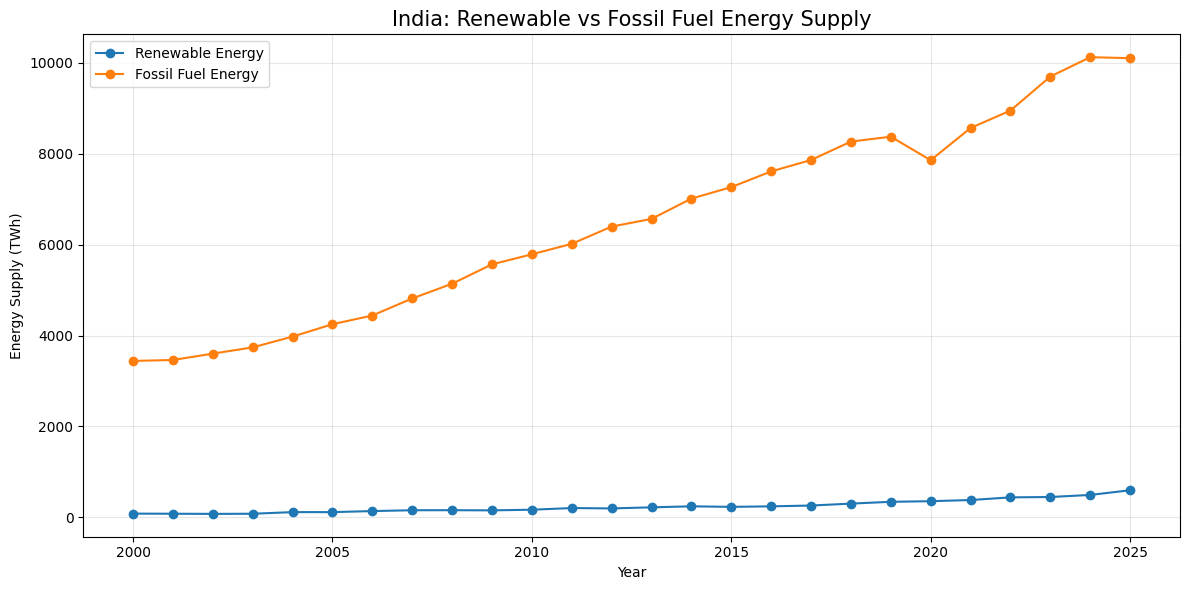

In [158]:
# Extract India's energy quantity data

india_quantity_data = energy_quantity_data[
    energy_quantity_data["country"] == "India"
].sort_values("year")

# Create figure

plt.figure(figsize=(12, 6))

# Plot renewable energy quantity

plt.plot(
    india_quantity_data["year"],
    india_quantity_data["renewables_energy_twh"],
    marker="o",
    label="Renewable Energy"
)

# Plot fossil fuel energy quantity

plt.plot(
    india_quantity_data["year"],
    india_quantity_data["fossil_fuels_energy_twh"],
    marker="o",
    label="Fossil Fuel Energy"
)

# Add chart details

plt.title("India: Renewable vs Fossil Fuel Energy Supply", fontsize=15)
plt.xlabel("Year")
plt.ylabel("Energy Supply (TWh)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart

plt.savefig(
    VISUALS_DIR / "02_india_energy_quantities.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Latest common comparison year: 2025


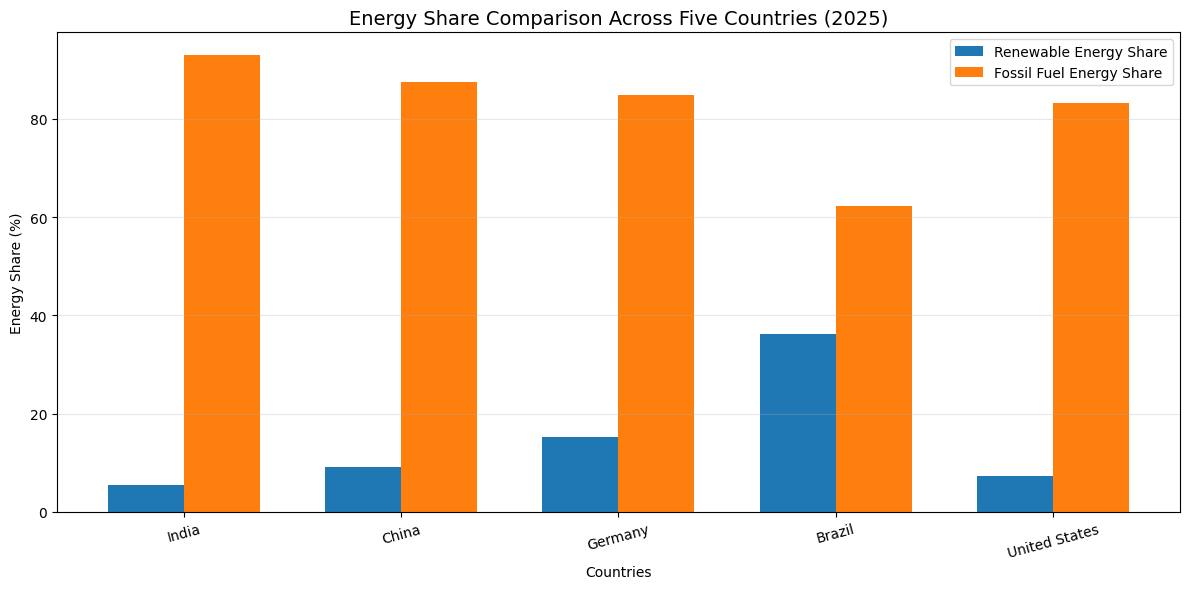

In [159]:
# Identify years with complete energy-share data

complete_share_data = energy_analysis.dropna(
    subset=share_columns
).copy()

country_year_sets = []

for country in countries:

    available_years = set(
        complete_share_data.loc[
            complete_share_data["country"] == country,
            "year"
        ].unique()
    )

    country_year_sets.append(available_years)

# Find years available for all five countries

common_years = set.intersection(*country_year_sets)

if not common_years:
    raise ValueError(
        "No common year with complete share data exists "
        "for all five countries."
    )

comparison_year = max(common_years)

print("Latest common comparison year:", comparison_year)

# Extract the selected year

country_comparison = complete_share_data[
    complete_share_data["year"] == comparison_year
].set_index("country").reindex(countries)

# Create grouped bar chart

x = np.arange(len(countries))
bar_width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - bar_width / 2,
    country_comparison["renewables_energy_share_pct"],
    bar_width,
    label="Renewable Energy Share"
)

plt.bar(
    x + bar_width / 2,
    country_comparison["fossil_fuels_energy_share_pct"],
    bar_width,
    label="Fossil Fuel Energy Share"
)

plt.title(
    f"Energy Share Comparison Across Five Countries ({comparison_year})",
    fontsize=14
)

plt.xlabel("Countries")
plt.ylabel("Energy Share (%)")

plt.xticks(x, countries, rotation=15)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save chart

plt.savefig(
    VISUALS_DIR / "03_global_energy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

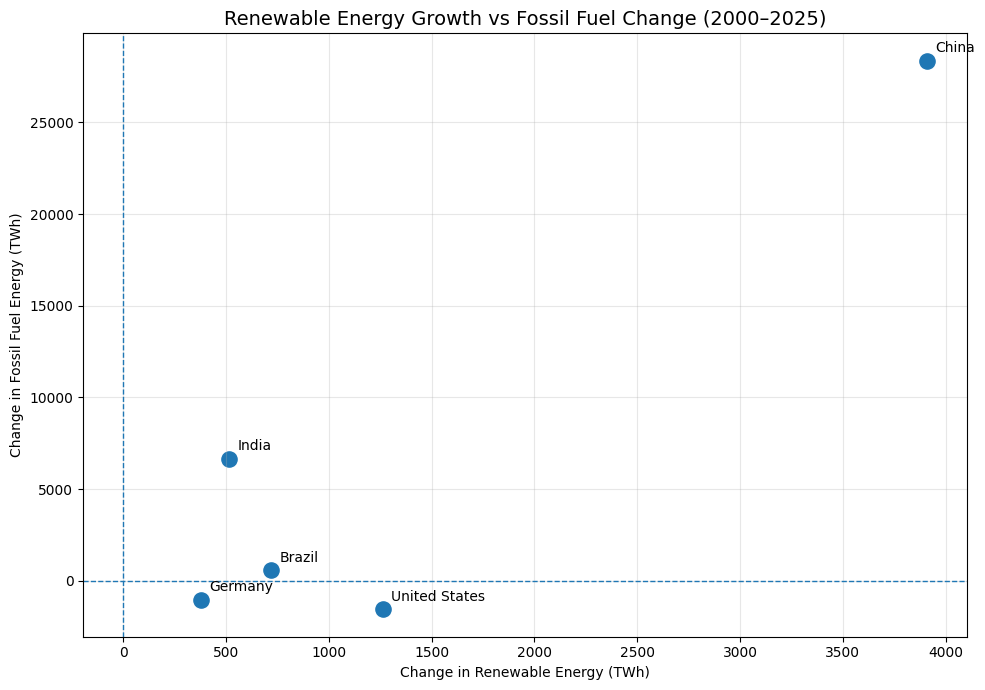

In [160]:
# Prepare data for scatter plot

scatter_data = comparison_table.dropna(
    subset=[
        "renewables_energy_twh_change",
        "fossil_fuels_energy_twh_change"
    ]
).copy()

# Create scatter plot

plt.figure(figsize=(10, 7))

plt.scatter(
    scatter_data["renewables_energy_twh_change"],
    scatter_data["fossil_fuels_energy_twh_change"],
    s=120
)

# Add country labels

for _, row in scatter_data.iterrows():

    plt.annotate(
        row["country"],
        (
            row["renewables_energy_twh_change"],
            row["fossil_fuels_energy_twh_change"]
        ),
        xytext=(6, 6),
        textcoords="offset points"
    )

# Add zero reference lines

plt.axhline(y=0, linewidth=1, linestyle="--")
plt.axvline(x=0, linewidth=1, linestyle="--")

# Add chart details

plt.title(
    "Renewable Energy Growth vs Fossil Fuel Change (2000–2025)",
    fontsize=14
)

plt.xlabel("Change in Renewable Energy (TWh)")
plt.ylabel("Change in Fossil Fuel Energy (TWh)")

plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart

plt.savefig(
    VISUALS_DIR / "05_energy_replacement_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [161]:
print("GREEN MIRAGE VISUALIZATION REPORT")
print("--------------------------------")

for file in sorted(VISUALS_DIR.glob("*.png")):
    print(file.name)

print("\nTotal visualizations:", len(list(VISUALS_DIR.glob("*.png"))))

GREEN MIRAGE VISUALIZATION REPORT
--------------------------------
01_india_energy_transition.png
02_india_energy_quantities.png
03_global_energy_comparison.png
04_renewable_energy_heatmap.png
05_energy_replacement_test.png

Total visualizations: 5


In [162]:
# Select important comparison columns

final_comparison = comparison_table[
    [
        "country",
        "renewables_energy_twh_2000",
        "renewables_energy_twh_2025",
        "renewables_energy_twh_change",
        "Renewables_Change_Percent",
        "fossil_fuels_energy_twh_2000",
        "fossil_fuels_energy_twh_2025",
        "fossil_fuels_energy_twh_change",
        "Fossil_Fuel_Change_Percent"
    ]
].copy()

print("FINAL COUNTRY ENERGY COMPARISON")
print("--------------------------------")

display(final_comparison.round(2))

FINAL COUNTRY ENERGY COMPARISON
--------------------------------


,country,renewables_energy_twh_2000,renewables_energy_twh_2025,renewables_energy_twh_change,Renewables_Change_Percent,fossil_fuels_energy_twh_2000,fossil_fuels_energy_twh_2025,fossil_fuels_energy_twh_change,Fossil_Fuel_Change_Percent
0,India,84.30,597.94,513.64,609.27,3442.30,10099.89,6657.59,193.41
1,China,231.47,4140.76,3909.29,1688.90,11085.26,39442.56,28357.30,255.81
2,Germany,47.27,423.09,375.82,795.02,3391.78,2366.79,-1024.99,-30.22
3,Brazil,403.30,1123.69,720.39,178.62,1346.81,1937.31,590.50,43.84
4,United States,621.09,1882.98,1261.89,203.17,23228.73,21677.24,-1551.50,-6.68


In [163]:
# Prepare country comparison results

share_ranking = country_comparison.reset_index()[
    [
        "country",
        "renewables_energy_share_pct",
        "fossil_fuels_energy_share_pct"
    ]
].copy()

# Rank countries by renewable energy share

share_ranking = share_ranking.sort_values(
    "renewables_energy_share_pct",
    ascending=False
)

share_ranking["Renewable_Rank"] = range(
    1, len(share_ranking) + 1
)

print("COUNTRY RANKING BY RENEWABLE ENERGY SHARE")
print("Comparison year:", comparison_year)

display(share_ranking.round(2))

COUNTRY RANKING BY RENEWABLE ENERGY SHARE
Comparison year: 2025


,country,renewables_energy_share_pct,fossil_fuels_energy_share_pct,Renewable_Rank
3,Brazil,36.14,62.32,1
2,Germany,15.17,84.83,2
1,China,9.19,87.55,3
4,United States,7.22,83.17,4
0,India,5.51,92.99,5


In [164]:
# Select India's observations

india_analysis = energy_analysis[
    energy_analysis["country"] == "India"
].copy()

# Indicators to investigate

india_indicators = {
    "total_energy_twh": "Total Energy Supply",
    "renewables_energy_twh": "Renewable Energy Supply",
    "fossil_fuels_energy_twh": "Fossil Fuel Energy Supply",
    "renewables_energy_share_pct": "Renewable Energy Share",
    "fossil_fuels_energy_share_pct": "Fossil Fuel Energy Share"
}

india_results = []

for column, label in india_indicators.items():

    valid_data = india_analysis[
        ["year", column]
    ].dropna().sort_values("year")

    if len(valid_data) >= 2:

        first = valid_data.iloc[0]
        last = valid_data.iloc[-1]

        india_results.append({
            "Indicator": label,
            "Starting_Year": int(first["year"]),
            "Starting_Value": first[column],
            "Ending_Year": int(last["year"]),
            "Ending_Value": last[column],
            "Absolute_Change": last[column] - first[column]
        })

india_trend = pd.DataFrame(india_results)

print("INDIA: HISTORICAL ENERGY ANALYSIS")

display(india_trend.round(2))

INDIA: HISTORICAL ENERGY ANALYSIS


,Indicator,Starting_Year,Starting_Value,Ending_Year,Ending_Value,Absolute_Change
0,Total Energy Supply,2000,3574.39,2025,10860.91,7286.52
1,Renewable Energy Supply,2000,84.30,2025,597.94,513.64
2,Fossil Fuel Energy Supply,2000,3442.30,2025,10099.89,6657.59
3,Renewable Energy Share,2000,2.36,2025,5.51,3.15
4,Fossil Fuel Energy Share,2000,96.30,2025,92.99,-3.31


In [165]:
# Create a country-wise pattern summary

pattern_summary = comparison_table[
    [
        "country",
        "Renewables_Change_Percent",
        "Fossil_Fuel_Change_Percent",
        "Observed_Pattern"
    ]
].copy()

print("OBSERVED ENERGY TRANSITION PATTERNS")
print("-----------------------------------")

display(pattern_summary.round(2))

print("\nPATTERN DISTRIBUTION")

display(
    pattern_summary["Observed_Pattern"]
    .value_counts()
    .rename_axis("Energy Pattern")
    .reset_index(name="Number of Countries")
)

OBSERVED ENERGY TRANSITION PATTERNS
-----------------------------------


,country,Renewables_Change_Percent,Fossil_Fuel_Change_Percent,Observed_Pattern
0,India,609.27,193.41,Both renewable and fossil energy increased
1,China,1688.90,255.81,Both renewable and fossil energy increased
2,Germany,795.02,-30.22,Renewables increased; fossil fuels decreased
3,Brazil,178.62,43.84,Both renewable and fossil energy increased
4,United States,203.17,-6.68,Renewables increased; fossil fuels decreased



PATTERN DISTRIBUTION


,Energy Pattern,Number of Countries
0,Both renewable and fossil energy increased,3
1,Renewables increased; fossil fuels decreased,2


In [166]:
# Generate findings using the actual comparison results

findings = []

findings.append("GREEN MIRAGE - RESEARCH FINDINGS")
findings.append("=" * 50)

for _, row in comparison_table.iterrows():

    country = row["country"]

    renewable_change = row["Renewables_Change_Percent"]
    fossil_change = row["Fossil_Fuel_Change_Percent"]

    renewable_absolute = row["renewables_energy_twh_change"]
    fossil_absolute = row["fossil_fuels_energy_twh_change"]

    findings.append(f"\nCountry: {country}")

    if pd.isna(renewable_change) or pd.isna(fossil_change):

        findings.append(
            "Insufficient endpoint data for a complete comparison."
        )

        continue

    findings.append(
        f"Renewable energy quantity change: "
        f"{renewable_absolute:.2f} TWh"
    )

    findings.append(
        f"Fossil fuel energy quantity change: "
        f"{fossil_absolute:.2f} TWh"
    )

    findings.append(
        f"Renewable energy relative change: "
        f"{renewable_change:.2f}%"
    )

    findings.append(
        f"Fossil fuel energy relative change: "
        f"{fossil_change:.2f}%"
    )

    findings.append(
        f"Observed pattern: {row['Observed_Pattern']}"
    )

print("\n".join(findings))

GREEN MIRAGE - RESEARCH FINDINGS

Country: India
Renewable energy quantity change: 513.64 TWh
Fossil fuel energy quantity change: 6657.59 TWh
Renewable energy relative change: 609.27%
Fossil fuel energy relative change: 193.41%
Observed pattern: Both renewable and fossil energy increased

Country: China
Renewable energy quantity change: 3909.29 TWh
Fossil fuel energy quantity change: 28357.30 TWh
Renewable energy relative change: 1688.90%
Fossil fuel energy relative change: 255.81%
Observed pattern: Both renewable and fossil energy increased

Country: Germany
Renewable energy quantity change: 375.82 TWh
Fossil fuel energy quantity change: -1024.99 TWh
Renewable energy relative change: 795.02%
Fossil fuel energy relative change: -30.22%
Observed pattern: Renewables increased; fossil fuels decreased

Country: Brazil
Renewable energy quantity change: 720.39 TWh
Fossil fuel energy quantity change: 590.50 TWh
Renewable energy relative change: 178.62%
Fossil fuel energy relative change: 43.8

In [167]:
# Generate an evidence-based preliminary conclusion

conclusion = []

conclusion.append("GREEN MIRAGE - PROJECT CONCLUSION")
conclusion.append("=" * 50)

conclusion.append(
    "\nThis project investigated renewable energy growth "
    "and fossil fuel consumption across five selected countries."
)

conclusion.append(
    "\nThe analysis compared energy quantities and energy shares "
    "to distinguish changes in absolute energy supply from "
    "changes in the overall energy mix."
)

complete_results = comparison_table.dropna(
    subset=[
        "Renewables_Change_Percent",
        "Fossil_Fuel_Change_Percent"
    ]
)

if complete_results.empty:

    conclusion.append(
        "\nThe available endpoint data was insufficient to "
        "produce a complete five-country comparison."
    )

else:

    both_increased = len(
        complete_results[
            (complete_results["renewables_energy_twh_change"] > 0) &
            (complete_results["fossil_fuels_energy_twh_change"] > 0)
        ]
    )

    renewable_up_fossil_down = len(
        complete_results[
            (complete_results["renewables_energy_twh_change"] > 0) &
            (complete_results["fossil_fuels_energy_twh_change"] < 0)
        ]
    )

    conclusion.append(
        f"\nCountries with increases in both energy quantities: "
        f"{both_increased}"
    )

    conclusion.append(
        f"Countries with renewable growth and fossil-fuel decline: "
        f"{renewable_up_fossil_down}"
    )

conclusion.append(
    "\nThese findings describe observed changes between available "
    "starting and ending observations. They do not establish "
    "causation or prove that renewable energy growth directly "
    "caused changes in fossil-fuel consumption."
)

conclusion.append(
    "\nData availability, measurement methodology and the "
    "selected comparison period should be considered when "
    "interpreting the results."
)

print("\n".join(conclusion))

GREEN MIRAGE - PROJECT CONCLUSION

This project investigated renewable energy growth and fossil fuel consumption across five selected countries.

The analysis compared energy quantities and energy shares to distinguish changes in absolute energy supply from changes in the overall energy mix.

Countries with increases in both energy quantities: 3
Countries with renewable growth and fossil-fuel decline: 2

These findings describe observed changes between available starting and ending observations. They do not establish causation or prove that renewable energy growth directly caused changes in fossil-fuel consumption.

Data availability, measurement methodology and the selected comparison period should be considered when interpreting the results.


In [168]:
from pathlib import Path

# Create an output folder

OUTPUT_DIR = Path("green_mirage_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Store our analysis tables

export_tables = {
    "final_country_comparison": final_comparison,
    "renewable_energy_ranking": share_ranking,
    "india_energy_trends": india_trend,
    "energy_transition_patterns": pattern_summary,
    "country_data_coverage": coverage,
    "indicator_data_coverage": coverage_details,
    "missing_value_report": missing_report
}

# Export each table as a CSV file

for filename, table in export_tables.items():

    table.to_csv(
        OUTPUT_DIR / f"{filename}.csv",
        index=False
    )

# Save research findings

with open(
    OUTPUT_DIR / "research_findings.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write("\n".join(findings))

# Save preliminary conclusion

with open(
    OUTPUT_DIR / "project_conclusion.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write("\n".join(conclusion))


print("PROJECT RESULTS EXPORTED SUCCESSFULLY!")

print("\nExported files:")

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)

PROJECT RESULTS EXPORTED SUCCESSFULLY!

Exported files:
country_data_coverage.csv
energy_transition_patterns.csv
final_country_comparison.csv
india_energy_trends.csv
indicator_data_coverage.csv
missing_value_report.csv
project_conclusion.txt
renewable_energy_ranking.csv
research_findings.txt


# 🔬 Research Methodology

## Dataset Source

The project uses the Global Energy Dataset published by Our World in Data.

## Research Scope

Five countries were selected:
- India
- China
- Germany
- Brazil
- United States

The analysis focuses on the period 2000–2025.

## Methodology

1. Collected energy data from the official OWID dataset.
2. Selected relevant energy indicators.
3. Filtered the dataset by country and year.
4. Examined missing values and duplicate observations.
5. Prepared separate datasets for energy quantities and energy shares.
6. Compared renewable and fossil-fuel energy changes.
7. Created visualizations to identify trends and patterns.
8. Generated research findings based on the observed data.

## Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

# ⚠️ Limitations of the Study

- The analysis focuses on only five selected countries and does not represent the entire world.
- Some indicators may contain missing observations.
- The availability of historical data may differ across countries.
- The comparison between 2000 and 2025 does not capture every annual fluctuation.
- Energy quantities and energy shares represent different measurements and must be interpreted separately.
- The analysis identifies associations and observed changes but does not establish causation.
- Population growth, economic development and changing energy demand may influence the observed patterns.

These limitations should be considered when interpreting the research findings.

In [169]:
# GREEN MIRAGE - FINAL PROJECT VALIDATION

print("GREEN MIRAGE FINAL AUDIT")
print("=" * 40)

checks = {
    "Five countries included": set(countries).issubset(
        set(energy_analysis["country"].dropna())
    ),

    "Comparison table generated": len(final_comparison) == 5,

    "Country ranking generated": len(share_ranking) == 5,

    "Five visualizations saved": len(
        list(VISUALS_DIR.glob("*.png"))
    ) == 5,

    "CSV reports exported": len(
        list(OUTPUT_DIR.glob("*.csv"))
    ) >= 7,

    "Research findings saved": (
        OUTPUT_DIR / "research_findings.txt"
    ).exists(),

    "Conclusion saved": (
        OUTPUT_DIR / "project_conclusion.txt"
    ).exists()
}

for task, status in checks.items():
    print(
        ("PASS" if status else "CHECK"),
        "-",
        task
    )

print("\nCompleted checks:", sum(checks.values()), "/", len(checks))

GREEN MIRAGE FINAL AUDIT
PASS - Five countries included
PASS - Comparison table generated
PASS - Country ranking generated
PASS - Five visualizations saved
PASS - CSV reports exported
PASS - Research findings saved
PASS - Conclusion saved

Completed checks: 7 / 7


In [170]:
print("SAVED VISUALIZATION FILES")
print("-------------------------")

saved_charts = sorted(VISUALS_DIR.glob("*.png"))

for chart in saved_charts:
    print(chart.name)

print("\nTotal charts found:", len(saved_charts))

SAVED VISUALIZATION FILES
-------------------------
01_india_energy_transition.png
02_india_energy_quantities.png
03_global_energy_comparison.png
04_renewable_energy_heatmap.png
05_energy_replacement_test.png

Total charts found: 5


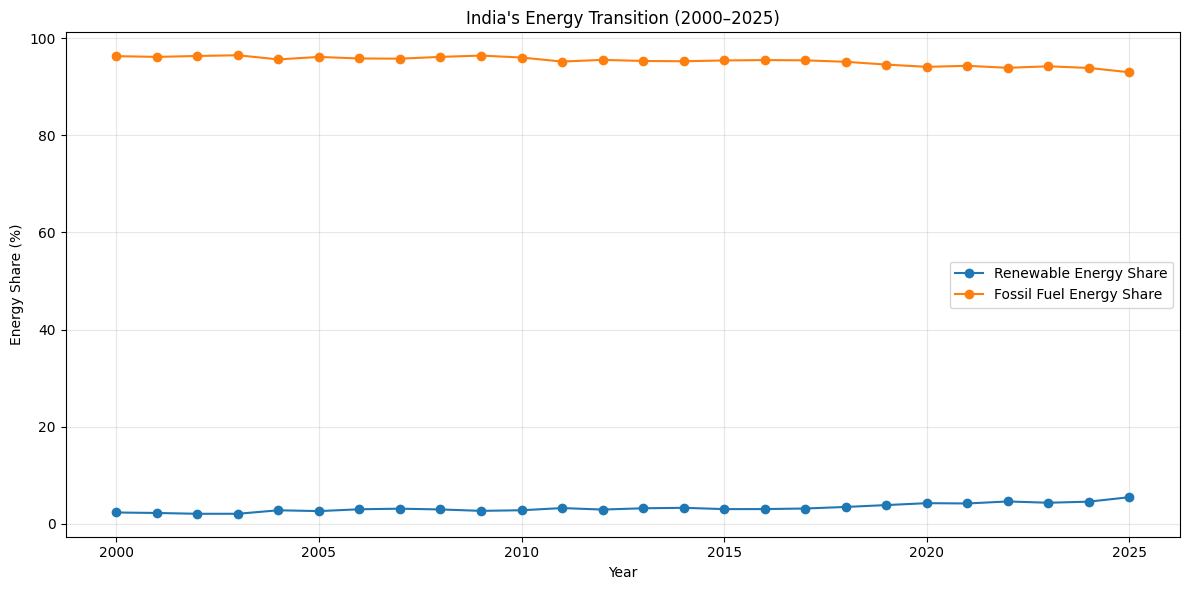

Chart 01 saved successfully!


In [171]:
VISUALS_DIR.mkdir(exist_ok=True)

india_share_data = energy_share_data[
    energy_share_data["country"] == "India"
].sort_values("year")

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    india_share_data["year"],
    india_share_data["renewables_energy_share_pct"],
    marker="o",
    label="Renewable Energy Share"
)

ax.plot(
    india_share_data["year"],
    india_share_data["fossil_fuels_energy_share_pct"],
    marker="o",
    label="Fossil Fuel Energy Share"
)

ax.set_title("India's Energy Transition (2000–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Energy Share (%)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    VISUALS_DIR / "01_india_energy_transition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Chart 01 saved successfully!")

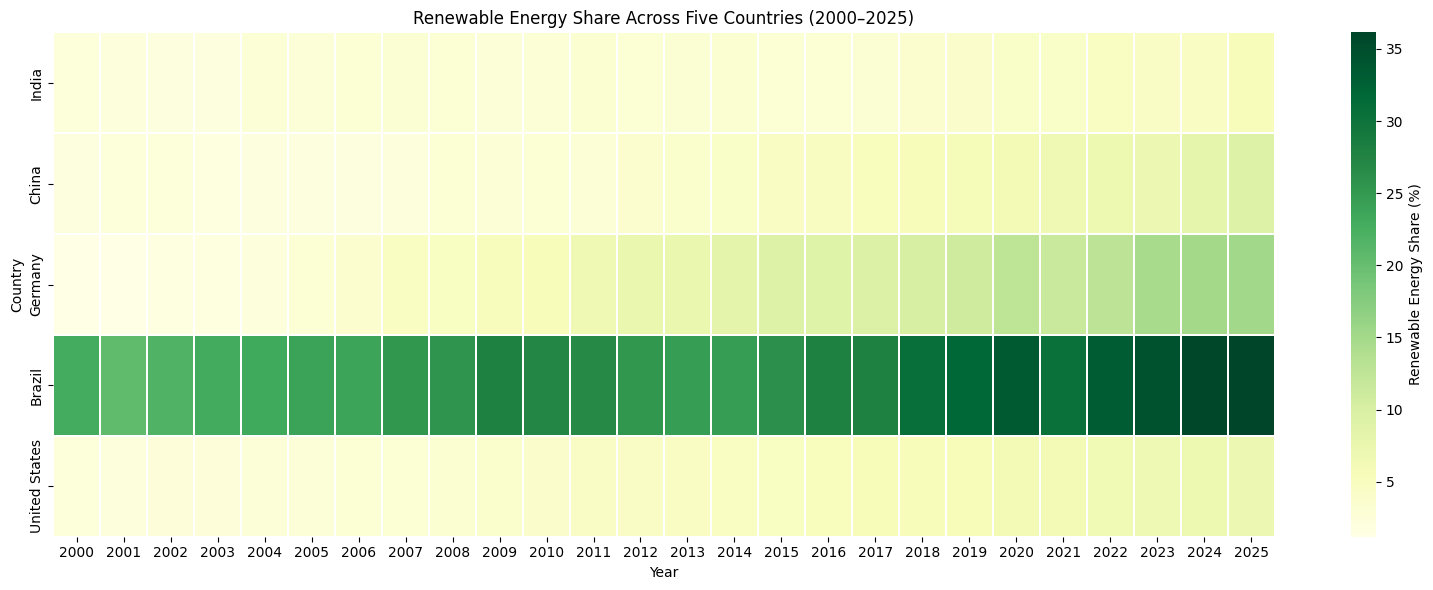

Chart 04 saved successfully!


In [172]:
heatmap_data = energy_share_data.pivot(
    index="country",
    columns="year",
    values="renewables_energy_share_pct"
)

heatmap_data = heatmap_data.reindex(countries)

heatmap_data = heatmap_data.reindex(
    sorted(heatmap_data.columns),
    axis=1
)

fig, ax = plt.subplots(figsize=(16, 6))

sns.heatmap(
    heatmap_data,
    cmap="YlGn",
    linewidths=0.3,
    cbar_kws={"label": "Renewable Energy Share (%)"},
    ax=ax
)

ax.set_title(
    "Renewable Energy Share Across Five Countries (2000–2025)"
)

ax.set_xlabel("Year")
ax.set_ylabel("Country")

plt.tight_layout()

fig.savefig(
    VISUALS_DIR / "04_renewable_energy_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Chart 04 saved successfully!")